1. **Data quality
2. **Bias
3. **Source criticism

(--------()

1. What is missing
2. Who or what is not in the table?
3. Who made the data, and why?



In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')

listings = pd.read_csv('data/listings_clean.csv', parse_dates=['first_review', 'last_review'])

print(listings.shape)

(4574, 73)


## Missing values: what is not there?

In [4]:
columns = ['price', 'review_scores_rating', 'beds', 'bathrooms_count']

(listings[columns].isna().mean() * 100).round(1)

price                   35.4
review_scores_rating    14.1
beds                     2.2
bathrooms_count          0.2
dtype: float64

In [6]:
pd.crosstab(listings['price'].isna(), listings['availability_365'] == 0)

availability_365,False,True
price,,
False,2953,4
True,127,1490


In [7]:
(listings['price'].isna().groupby(listings['room_type']).mean() * 100).round(0)

room_type
Entire home/apt    38.0
Hotel room         67.0
Private room       25.0
Shared room        21.0
Name: price, dtype: float64

In [8]:
pd.crosstab(listings['review_scores_rating'].isna(), listings['has_reviews'])

has_reviews,False,True
review_scores_rating,,
False,0,3930
True,644,0


## Does it make sense?

In [9]:
print(listings['id'].duplicated().sum())

0


In [13]:
listings.loc[listings['bathrooms_count'] == 0, 'bathrooms_text'].value_counts()

bathrooms_text
0 shared baths    24
0 baths           18
Name: count, dtype: int64

In [14]:
long_stay = listings['minimum_nights'] >= 28

print(long_stay.sum())
print((long_stay.mean() * 100).round(1))

188
4.1


1. How much is missing, and where?
2. Are there duplicates?
3. Are there values that cannot be true? (a price of 0, a date in the future)
4. Are there values that are true, but mean something else than the column name says?

## Ratings: when almost everyone gets five stars

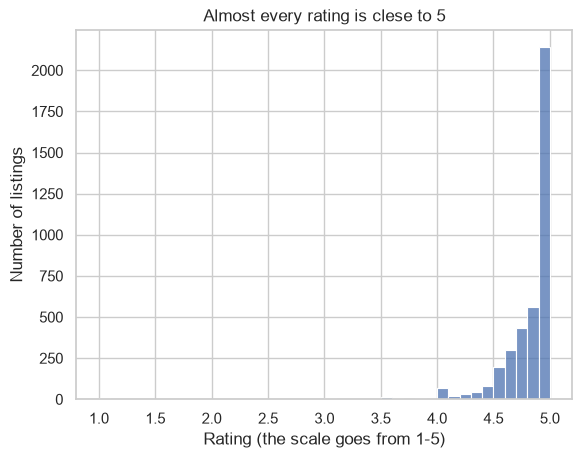

In [16]:
rated = listings[listings['has_reviews']]

fig, ax = plt.subplots()

sns.histplot(data=rated, x = 'review_scores_rating', bins=40, ax=ax)

ax.set_title('Almost every rating is clese to 5')
ax.set_xlabel('Rating (the scale goes from 1-5)')
ax.set_ylabel('Number of listings')

plt.show()

In [17]:
perfect = rated['review_scores_rating'] == 5

print(len(rated))
print(perfect.sum())
print((perfect.mean() * 100).round(1))

3930
1484
37.8


In [19]:
review_group = pd.cut(
    rated['number_of_reviews'],
    bins=[0, 1, 5, 20, 10000],
    labels=['1 review', '2-5 reviews', '6-20 reviews', 'more than 20'],
)

perfect.groupby(review_group).agg(['count', 'mean']).round(2)

,count,mean
number_of_reviews,,
1 review,319,0.84
2-5 reviews,852,0.71
6-20 reviews,1271,0.38
more than 20,1488,0.08


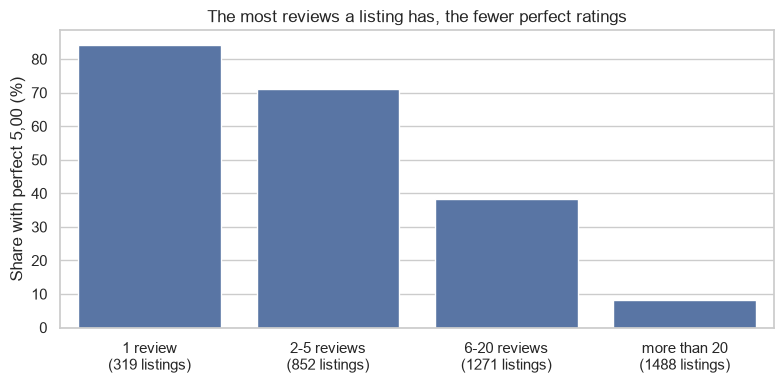

In [23]:
result = perfect.groupby(review_group).agg(['count', 'mean']).reset_index()

result['percent'] = result['mean'] * 100
result['label'] = result['number_of_reviews'].astype(str) + '\n('+ result['count'].astype(str) + ' listings)' # example: 1 revi

fig, ax = plt.subplots(figsize=(8,4))

sns.barplot(data=result, x='label', y='percent', ax=ax)

ax.set_title('The most reviews a listing has, the fewer perfect ratings')
ax.set_xlabel('')
ax.set_ylabel('Share with perfect 5,00 (%)')

plt.tight_layout()
plt.show()


In [25]:
rated['review_scores_rating'].groupby(review_group).median()

number_of_reviews
1 review        5.00
2-5 reviews     5.00
6-20 reviews    4.91
more than 20    4.86
Name: review_scores_rating, dtype: float64

selection bias

## Who is in the table, and who is not?

danas cemo konacno raditi ono sto je Aladdin obecavao jos prosle nedelje i u ponedeljak za danas, za cetvrtak...

: survivorship bias

In [26]:
first_year = listings['first_review'].dt.year
reviewed_2026 = listings['last_review'].dt.year == 2026

reviewed_2026.groupby(first_year).agg(['count', 'mean']).loc[2015:].round(2)

,count,mean
first_review,,
2015.0,116,0.53
2016.0,131,0.53
2017.0,148,0.53
2018.0,191,0.51
2019.0,234,0.55
2020.0,96,0.54
2021.0,159,0.58
2022.0,332,0.52
2023.0,565,0.59


Can say: "Of the listings that exist today, 116 got their review in 2015"
Can not  say: "In 2015, 116 listing started"

In [ ]:
print (len(listings))
print(listings['host_id'].nunique())  # different hosts

listings['host_id'].value_counts().head(3)

4574
3591


host_id
271346174    49
410412637    37
60382478     24
Name: count, dtype: int64

## Source criiticism: where does the data come from?

In [29]:
listings['last_scraped'].value_counts()


last_scraped
2026-09-27    3486
2026-09-26    1088
Name: count, dtype: int64

is it measurement or a calculation?

In [30]:
difference = (listings['price'] * listings['estimated_occupancy_l365d'] - listings['estimated_revenue_l365d']).abs()

print(difference.max())
print((listings['estimated_occupancy_l365d'] ==0).sum())

0.5
1797


Before you trust a table, ask:

1. What is missing? How much, in wich columns, and is there a reason= (isna(.mean(, srosstab)))
2. Does it make sense? Duplicates, values that cannot be true, values that mean something else than their name. (duplicated(), value_count, and your own knowlage)
3. Who is in the table, and who is not? Is it a fair picture of what you want to describe? Think about survivors, aboyt who chooses to answer, and about who is not covered.
4. Who made it, how, when and why? Read the documentation. Check the licence, the date and the meaning of the columns.
5. Is it measured or calculated? By whom, and with which assumptions?
6. What ca it not tell me?